In [1]:
from anemone.experiment import *
from anemone.forwards import ForwardFD, ForwardFD2
import matplotlib.pyplot as plt
import numpy as np
from anemone import constants as c

In [2]:
tx = Loop([0, 1000], [0,0], [0,0])
rx = Receiver(x=100, y=100)

# tx = Loop.square(25)
# rx = Receiver()

#frq = torch.arange(1,51)*2000
frq = torch.logspace(-2, 5, 51)
fwr = ForwardFD(tx, rx, frq)
fwr2 = ForwardFD2(tx, rx, frq)

c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:127: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [3]:
rxs = Receiver(x = [0, 100, 150, 200], y=5)
rxs.xyz.shape

torch.Size([4, 3])

In [4]:
rxs = Receiver(x = [0, 100, 200], y=[5, 10])
rxs.xyz.shape

torch.Size([6, 3])

In [5]:
fwr = ForwardFD(tx, rxs, frq)
fwr2 = ForwardFD2(tx, rxs, frq)

In [6]:
sigma = 1/torch.tensor([40, 200, 80])
thick = torch.tensor([30, 30])

# sigma = torch.ones(2)
# thick = torch.ones(1)*30

hz1 = fwr(sigma, thick)
hz2 = fwr2(sigma, thick)

c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:140: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  R = torch.tensor(R, dtype=torch.float64)


In [7]:
hz1.shape

torch.Size([6, 51])

ValueError: x and y must have same first dimension, but have shapes (51,) and (6, 51)

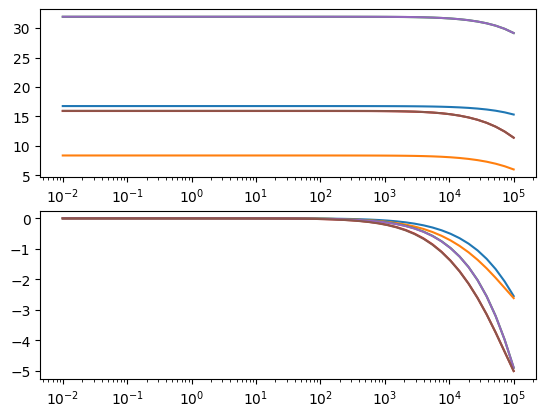

In [8]:
fig,axs = plt.subplots(2,1)
axs[0].semilogx(frq.numpy(), 1e3*hz1.numpy().T.real/c.mu0, label='reg')
axs[1].semilogx(frq.numpy(), 1e3*hz1.numpy().T.imag/c.mu0, label='reg')
axs[0].semilogx(frq.numpy(), 1e3*hz2.numpy().T.real/c.mu0, label='iws')
axs[1].semilogx(frq.numpy(), 1e3*hz2.numpy().T.imag/c.mu0, label='iws')
axs[1].legend()

In [9]:
#tx = Loop([0, 1000], [0,0], [0,0])
tx = Loop.square(25)
rx = Receiver(y = torch.logspace(0, 2, 31))

# tx = Loop.square(25)
# rx = Receiver()
frq = torch.tensor([2000, 2001])

fwr = ForwardFD(tx, rx, frq)
fwr2 = ForwardFD2(tx, rx, frq)

c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:27: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.y = torch.tensor(y, dtype=torch.float64)


In [10]:
sigma = 1/torch.tensor([40, 200, 80])
thick = torch.tensor([30, 30])

hz1 = fwr(sigma, thick)
hz2 = fwr2(sigma, thick).T

In [11]:
%%timeit
hz1 = fwr(sigma, thick)

197 ms ± 25.8 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [12]:
%%timeit
hz2 = fwr2(sigma, thick).T

84.2 ms ± 25.2 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [13]:
hz1.shape
hz2.shape

torch.Size([31, 2])

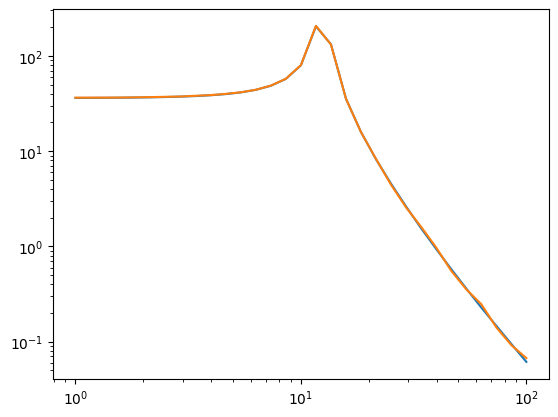

In [14]:
plt.figure()
plt.loglog(rx.y.numpy(), np.abs(1e3*hz1.numpy()[...,0].real/c.mu0), label='reg')
plt.loglog(rx.y.numpy(), np.abs(1e3*hz2.numpy()[...,0].real/c.mu0), label='reg')
# plt.plot(rx.y.numpy(), 1e3*hz2.numpy().real/c.mu0, label='iws')